In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [20]:
df = pd.read_csv('data/kits23_tumor_instance_data.csv')
print(len(df))
df.head()

559


,Unnamed: 0,case_id,tumor_instance,calculated_diameter_mm,spacing_z,spacing_y,spacing_x
0,0,case_00000,tumor_instance-1_annotation-1.nii.gz,31.20,0.5,0.919922,0.919922
1,1,case_00001,tumor_instance-1_annotation-1.nii.gz,18.06,0.5,0.798828,0.798828
2,2,case_00001,tumor_instance-2_annotation-1.nii.gz,25.34,0.5,0.798828,0.798828
3,3,case_00002,tumor_instance-1_annotation-1.nii.gz,49.03,1.0,0.939453,0.939453
4,4,case_00003,tumor_instance-1_annotation-1.nii.gz,32.72,1.0,0.855469,0.855469


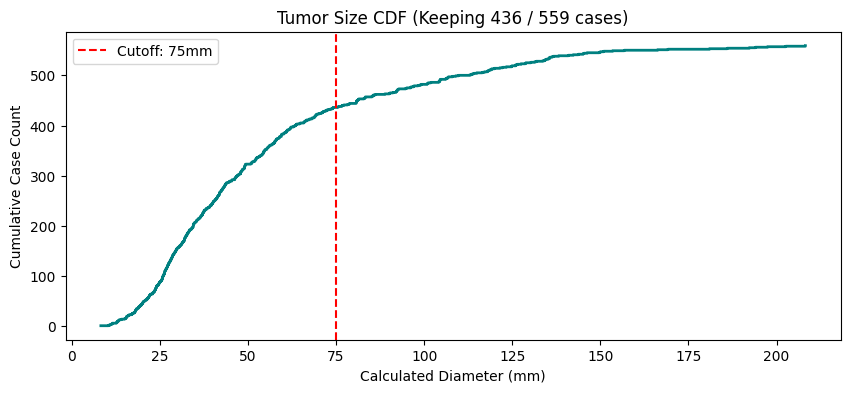

,Unnamed: 0,case_id,tumor_instance,calculated_diameter_mm,spacing_z,spacing_y,spacing_x
0,0,case_00000,tumor_instance-1_annotation-1.nii.gz,31.20,0.5,0.919922,0.919922
1,1,case_00001,tumor_instance-1_annotation-1.nii.gz,18.06,0.5,0.798828,0.798828
2,2,case_00001,tumor_instance-2_annotation-1.nii.gz,25.34,0.5,0.798828,0.798828
3,3,case_00002,tumor_instance-1_annotation-1.nii.gz,49.03,1.0,0.939453,0.939453
4,4,case_00003,tumor_instance-1_annotation-1.nii.gz,32.72,1.0,0.855469,0.855469
...,...,...,...,...,...,...,...
554,554,case_00586,tumor_instance-3_annotation-1.nii.gz,20.16,3.0,0.781250,0.781250
555,555,case_00586,tumor_instance-1_annotation-1.nii.gz,20.73,3.0,0.781250,0.781250
556,556,case_00586,tumor_instance-2_annotation-1.nii.gz,27.98,3.0,0.781250,0.781250
557,557,case_00587,tumor_instance-1_annotation-1.nii.gz,21.96,5.0,0.800781,0.800781


In [ ]:
def apply_threashold_and_plot(df, threshold):
    sorted_diameters = np.sort(df['calculated_diameter_mm'].dropna())
    y_vals = np.arange(1, len(sorted_diameters) + 1)

    # Plot CDF
    plt.figure(figsize=(10, 4))
    plt.step(sorted_diameters, y_vals, color='teal', where='post', linewidth=2)
    plt.axvline(x=threshold, color='red', linestyle='--', label=f'Cutoff: {threshold}mm')
    
    # Filter dataset
    kept_df = df[df['calculated_diameter_mm'] <= threshold].copy()
    
    plt.title(f"Tumor Size CDF (Keeping {len(kept_df)} / {len(df)} cases)")
    plt.xlabel("Calculated Diameter (mm)")
    plt.ylabel("Cumulative Case Count")
    plt.legend()
    plt.show()
    
    return kept_df

apply_threashold_and_plot(df, 75)